# 01 · Découvrir et préparer les données (français ↔ bambara)

**But du projet.** Construire un détecteur de langue et un traducteur français ↔ bambara, étape par étape.
**But de ce notebook.** Télécharger le corpus de traduction, le regarder de près, le nettoyer et le ranger dans `data/processed/` pour les notebooks suivants.

| | |
|---|---|
| **Durée** | quelques minutes |
| **Matériel** | aucun GPU nécessaire |
| **Internet** | oui, pour le premier téléchargement (environ 2 Mo) |
| **Ce que tu obtiens** | `data/processed/train.tsv`, `val.tsv`, `test.tsv` |

**Les données.** MAFAND-MT (Masakhane) : des phrases de presse en français avec leur traduction en bambara. Licence **CC BY-NC-4.0** : usage non commercial, avec attribution. Le corpus est petit (environ 3 000 paires d'entraînement) et déjà découpé en `train` / `val` (aussi appelé `dev`) / `test`.

**Comment utiliser ce notebook.** Lance les cellules **dans l'ordre**, de haut en bas (touche `Maj + Entrée`). Lis le texte avant chaque cellule : il explique ce qu'elle fait et ce que tu dois obtenir.

## 1. Se repérer dans les dossiers

**Objectif.** Savoir où le projet range ses fichiers, quel que soit l'endroit où tu l'as décompressé sur ton ordinateur.

**Ce que fait la cellule.** Détecte le dossier racine du projet, crée les dossiers `data/raw`, `data/processed`, `models` et `results` s'ils n'existent pas, et règle deux options de confort pour Hugging Face.

**Ce que tu dois voir.** Une ligne `Racine du projet : /home/<toi>/nlp-bambara-ubuntu`.

> **Attention.** Si tu vois une erreur « Dossier du projet introuvable », tu n'as pas lancé Jupyter avec `bash lancer_jupyter.sh`.

In [1]:
import os
from pathlib import Path

# Ces deux réglages évitent des avertissements inutiles de Hugging Face.
os.environ["HF_HUB_DISABLE_SYMLINKS_WARNING"] = "1"
os.environ["TOKENIZERS_PARALLELISM"] = "false"

# Racine du projet = le dossier qui contient "data", "models", "results", "src"...
cwd = Path.cwd()
ROOT = cwd.parent if cwd.name == "notebooks" else cwd
if not (ROOT / "src").exists():
    raise RuntimeError(
        f"Dossier du projet introuvable depuis {cwd}. "
        "Lance Jupyter avec bash lancer_jupyter.sh (ou depuis le dossier du projet)."
    )

DATA_RAW = ROOT / "data" / "raw"
DATA_PROC = ROOT / "data" / "processed"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"
for folder in (DATA_RAW, DATA_PROC, MODELS, RESULTS):
    folder.mkdir(parents=True, exist_ok=True)

print("Racine du projet :", ROOT)

Racine du projet : /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl


## 2. Télécharger les données

**Objectif.** Récupérer les trois fichiers du corpus (entraînement, validation, test).

**Ce que fait la cellule.** Télécharge chaque fichier depuis le dépôt GitHub de Masakhane et le garde dans `data/raw/`. Les fichiers bruts ne sont **jamais modifiés** : si tu relances la cellule, elle réutilise la copie locale au lieu de retélécharger. Chaque ligne du fichier contient une phrase française et sa traduction bambara ; on les range dans un tableau (DataFrame) à deux colonnes `fr` et `bam`.

**Ce que tu dois voir.** Trois lignes : `train 3013 paires`, `val 1500 paires`, `test 1500 paires`.

> **Attention.** Pourquoi GitHub et pas Hugging Face ? Le jeu de données Hugging Face `masakhane/mafand` utilise un script de chargement que les versions récentes de la bibliothèque `datasets` ne supportent plus. Les fichiers viennent du dépôt `masakhane-io/lafand-mt`.

In [2]:
import json
import urllib.request

import pandas as pd

GITHUB = "https://raw.githubusercontent.com/masakhane-io/lafand-mt/main/data/json_files/fr-bam"
FILES = {"train": "train.json", "val": "dev.json", "test": "test.json"}

def download(split):
    # Copie locale : on ne retélécharge pas si le fichier est déjà là.
    local = DATA_RAW / f"mafand_fr-bam_{FILES[split]}"
    if local.exists():
        text = local.read_text(encoding="utf-8")
    else:
        with urllib.request.urlopen(f"{GITHUB}/{FILES[split]}") as resp:
            text = resp.read().decode("utf-8")
        local.write_text(text, encoding="utf-8")
    rows = [json.loads(line)["translation"] for line in text.splitlines() if line.strip()]
    return pd.DataFrame(rows)[["fr", "bam"]]

data = {split: download(split) for split in FILES}
for split, df in data.items():
    print(f"{split:6s} {len(df):5d} paires")

train   3013 paires
val     1500 paires
test    1500 paires


## 3. Premier regard sur les phrases

**Objectif.** Voir à quoi ressemblent vraiment les données avant de calculer quoi que ce soit.

**Ce que fait la cellule.** Affiche les cinq premières paires d'entraînement.

**Ce que tu dois voir.** Des phrases de presse (politique, économie, société) en français, avec leur traduction en bambara. Remarque les lettres spéciales du bambara : ɛ, ɔ, ɲ, ŋ.

> **Attention.** Une traduction humaine n'est jamais unique. Une même phrase française peut être traduite de plusieurs façons correctes, ce qui compliquera l'évaluation plus tard.

In [3]:
pd.set_option("display.max_colwidth", 140)
data["train"].head(5)

,fr,bam
0,"Parmi ces points, figurent la révision des réformes institutionnelles découlant de l’accord pour la paix, les questions sécuritaires et ...","O kɔnɔko yɔrɔw cɛla, fangabulonkow yɛlɛmaniw kɛli, minnu bɛ bɔ bɛnkansɛbɛn na bɛn kama, lakana ani yiriwali koɲɛw b’olu la."
1,"Sur place, le bureau de la Coordination des associations et ONG féminines de Kayes a déclaré qu’il attendait impatiemment cette 42ème se...","Kɛnɛ kan, Kayi musow ka tɔnw ani dɛmɛdonjɛkuluw ka kolatilenjɛkulu biro y’a dantigɛ k’ale tun kɔrɔtɔlen bɛ ka SEYƐSIYA ka nin waatilabaa..."
2,Rappelons qu’il s’agit de la deuxième délocalisation du CSA après celle de Kidal.,"An ka hakilijigin kɛ ko SEYƐSIYA taako filanan don yɔrɔ wɛrɛ, Kidali ta kɔfɛ."
3,Des membres de la société civile de Kayes ont salué l’initiative de délocaliser cette session du CSA dans leur région.,"Kayi jɛrɛjɛkuluw mɔgɔw ye SEYƐSIYA ka nin waatilabaara taako marabolo kɔnɔ hakilila fo,"
4,"Mme Fofana Sissoko Ramata, présidente régionale de la CAFO de Kayes, souligne que cette rencontre leur a permis de mieux comprendre l’ac...","Mmu Fofana Sisoko Ramata, Kayi marabolo KAFO perezidanmuso, y’a dajira ko nin ɲɔgɔnkunbɛn y’a to olu ka bɛnkansɛbɛn bɛn kama faamuya ka ɲɛ."


## 4. Statistiques : longueurs, doublons, lignes vides

**Objectif.** Repérer les problèmes de qualité : lignes vides, doublons, phrases anormalement longues ou courtes.

**Ce que fait la cellule.** Regroupe les trois découpages dans un seul tableau, compte les mots de chaque phrase, calcule le rapport de longueur bambara / français, puis trace trois histogrammes.

**Ce que tu dois voir.** `Lignes vides : 0`, quelques paires dupliquées (une dizaine au plus), et des histogrammes dont la plupart des phrases ont entre 10 et 40 mots. Le rapport de longueur est centré autour de 1 (une phrase et sa traduction ont une longueur voisine).

> **Attention.** Les histogrammes sont coupés à 100 mots (et à 4 pour le rapport) pour rester lisibles : quelques phrases très longues existent.

Lignes vides      : 0
Paires dupliquées : 8


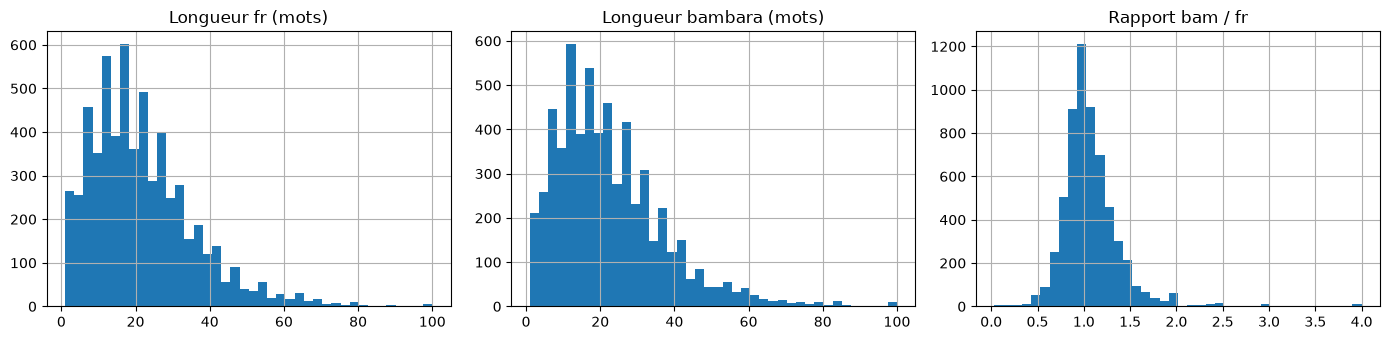

,len_fr,len_bam,ratio
count,6013.00,6013.00,6013.00
mean,21.83,22.49,1.08
std,14.42,14.94,0.34
min,1.00,1.00,0.03
25%,11.00,12.00,0.89
50%,19.00,20.00,1.00
75%,29.00,30.00,1.20
max,130.00,143.00,5.00


In [4]:
import matplotlib.pyplot as plt

full = pd.concat([df.assign(split=name) for name, df in data.items()], ignore_index=True)
full["len_fr"] = full["fr"].str.split().str.len()
full["len_bam"] = full["bam"].str.split().str.len()
full["ratio"] = full["len_bam"] / full["len_fr"].clip(lower=1)

print("Lignes vides      :", ((full["fr"].str.strip() == "") | (full["bam"].str.strip() == "")).sum())
print("Paires dupliquées :", full.duplicated(subset=["fr", "bam"]).sum())

fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
full["len_fr"].clip(upper=100).hist(bins=40, ax=axes[0]); axes[0].set_title("Longueur fr (mots)")
full["len_bam"].clip(upper=100).hist(bins=40, ax=axes[1]); axes[1].set_title("Longueur bambara (mots)")
full["ratio"].clip(upper=4).hist(bins=40, ax=axes[2]); axes[2].set_title("Rapport bam / fr")
plt.tight_layout()
plt.show()

full[["len_fr", "len_bam", "ratio"]].describe().round(2)

## 5. Paires suspectes et caractères du bambara

**Objectif.** Détecter d'éventuelles erreurs d'alignement (une phrase mal associée à sa traduction) et vérifier que les lettres spéciales du bambara sont bien présentes.

**Ce que fait la cellule.** Isole les paires dont le rapport de longueur est très éloigné de 1 (plus de 2,5 fois ou moins de 0,4 fois) et les affiche. Puis compte les caractères non ASCII du texte bambara.

**Ce que tu dois voir.** Une cinquantaine de paires suspectes. Parmi les caractères, les plus fréquents devraient être `ɛ`, `ɔ`, `ɲ`, `ŋ` et des lettres accentuées.

> **Attention.** Une paire suspecte n'est pas forcément fausse : certaines phrases se traduisent vraiment par beaucoup plus ou moins de mots. C'est à toi de les relire, tu comprends la langue.

In [5]:
from collections import Counter

suspects = full[(full["ratio"] > 2.5) | (full["ratio"] < 0.4)]
print(len(suspects), "paires suspectes. Les 10 premières :")
display(suspects[["split", "fr", "bam", "ratio"]].head(10))

chars = Counter("".join(full["bam"]))
special = {c: n for c, n in chars.items() if ord(c) > 127}
print("Caractères non ASCII les plus fréquents :")
sorted(special.items(), key=lambda x: -x[1])[:30]

58 paires suspectes. Les 10 premières :


,split,fr,bam,ratio
94,train,"Le montant total des irrégularités financières, ci-dessous, s’élève à 27 435 650 FCFA.","Nafolo kɛcogoya juguw hakɛ bakuruba, min bɛ nin dugumana na, bɛ ta i jɔ sefawari dɔrɔmɛ 27 087 130 (miliyon mugan ni wolonwula ani ba b...",2.692308
145,train,Esprits jaloux Les hommes me fuient parce que je suis possédéeHYPERLINK “https://saheltribune.com/les-maris-ou-les-femmes-de-nuit-sont-...,Kɛleyabagatɔ hakiliw - Cɛw bɛ boli n ɲɛ k’a da a kan sigifɛnw bɛ n kɔ. HYPERLINK « https : // saheltribune.com / sufɛla - cɛw - wa...,2.882353
210,train,J’ai été embarqué manu-militari et frappé jusqu’au commissariat.,"U ye n minɛ ka bila u ka mobili kɔnɔ ni sɔrɔdasiyafanga ye, ni ka n bugɔ fo ka taa an se polisiso la.",3.000000
247,train,précise-t-il.,A y’o pereperelatigɛ.,3.000000
252,train,dit-il.,A ko ten.,3.000000
411,train,"A. C. Le 19 juin 2021, la salle de conférence du comité national olympique et sportif du Mali a servi de cadre à la remise officielle de...","ASE. - Zuwɛnkalo tile 19 san 2021, Mali olɛnpikiko ani farikoloɲɛnajɛko",0.282051
453,train,"Diaty N’Diaye Hier, lundi 28 juin 2021, le Premier ministre, Dr. Choguel Kokalla Maïga s’est rendu à la Maison de la Presse du Mali (Bam...",Jati Njayi.,0.058824
604,train,"La surreprésentation des populations du Nord (10 % de la population nationale) Elle sera difficilement acceptable pour le Mali, en plus ...",Kaɲaka jamaw tɔgɔlamɔgɔw cayali k’a damatɛmɛ ( jamana jama 10% ).,0.392857
629,train,soulignent-ils.,U y’o dantigɛ.,3.000000
769,train,Ses fans attendaient.,"A kanu bɛɛ mɔgɔ minnu na, tun bɛ k’a seginni makɔnɔ so,",4.000000


Caractères non ASCII les plus fréquents :


[('ɛ', 32758),
 ('ɔ', 26316),
 ('’', 5583),
 ('ɲ', 5053),
 ('\xa0', 1113),
 ('Ɛ', 844),
 ('«', 350),
 ('»', 337),
 ('Ɲ', 257),
 ('–', 228),
 ('ŋ', 186),
 ('Ɔ', 66),
 ('°', 28),
 ('…', 17),
 ('‘', 14),
 ('”', 11),
 ('“', 8),
 ('ℇ', 8),
 ('Ŋ', 7),
 ('é', 5),
 ('¸', 3),
 ('²', 1)]

## 6. Chercher une fuite de données

**Objectif.** S'assurer que le modèle n'est pas évalué sur des phrases qu'il a déjà vues à l'entraînement : ce serait de la triche involontaire.

**Ce que fait la cellule.** Compte les phrases françaises présentes à la fois dans `train` et dans `val` ou `test`.

**Ce que tu dois voir.** Quelques dizaines de phrases en commun (environ 7 avec `val` et 37 avec `test`).

> **Attention.** Si on ne les retire pas, le score sur le test sera trop optimiste. L'étape suivante les retire du `train`.

In [6]:
train_fr = set(data["train"]["fr"])
for name in ("val", "test"):
    common = train_fr & set(data[name]["fr"])
    print(f"phrases fr communes train/{name} : {len(common)}")

phrases fr communes train/val : 7
phrases fr communes train/test : 37


## 7. Nettoyer et sauvegarder

**Objectif.** Produire les fichiers propres que tous les autres notebooks utiliseront.

**Ce que fait la cellule.** Normalise les espaces, retire les lignes vides et les doublons, retire du `train` toute phrase française qui apparaît dans `val` ou `test`, puis écrit `train.tsv`, `val.tsv` et `test.tsv` dans `data/processed/` (format texte séparé par des tabulations, colonnes `fr` et `bam`).

**Ce que tu dois voir.** `train : 3013 -> 2970 paires (fuite retirée)` environ, puis trois lignes confirmant l'écriture des fichiers. Vérifie dans ton gestionnaire de fichiers que le dossier `data/processed` contient bien ces trois fichiers.

> **Attention.** Les fichiers `.tsv` sont de simples fichiers texte : tu peux les ouvrir dans un tableur (LibreOffice, Excel) ou un éditeur de texte pour les regarder.

In [7]:
def clean(df):
    df = df.copy()
    for col in ("fr", "bam"):
        df[col] = df[col].astype(str).str.replace(r"\s+", " ", regex=True).str.strip()
    df = df[(df["fr"] != "") & (df["bam"] != "")]
    return df.drop_duplicates(subset=["fr", "bam"]).reset_index(drop=True)

clean_data = {name: clean(df) for name, df in data.items()}

# On retire du train toute phrase française qui apparaît aussi dans val ou test.
held_out_fr = set(clean_data["val"]["fr"]) | set(clean_data["test"]["fr"])
before = len(clean_data["train"])
clean_data["train"] = clean_data["train"][~clean_data["train"]["fr"].isin(held_out_fr)].reset_index(drop=True)
print(f"train : {before} -> {len(clean_data['train'])} paires (fuite retirée)")

for name, df in clean_data.items():
    path = DATA_PROC / f"{name}.tsv"
    df.to_csv(path, sep="\t", index=False, encoding="utf-8")
    print(f"{name:6s} {len(df):5d} paires -> {path}")

train : 3012 -> 2970 paires (fuite retirée)
train   2970 paires -> /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/data/processed/train.tsv
val     1499 paires -> /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/data/processed/val.tsv
test    1499 paires -> /mnt/c/Users/RobotsMali-Victus/Desktop/nlp-bambara/nlp-bambara-wsl/data/processed/test.tsv


## Suite

- **Notebook 02** : un détecteur de langue (aucun GPU nécessaire).
- **Notebook 03** : la traduction de référence avec NLLB-200, sans entraînement.

*Données : MAFAND-MT, Masakhane, CC BY-NC-4.0. Les textes sources sont des articles de presse dont les licences varient selon les sites.*